# Chapter 42: Vector Databases

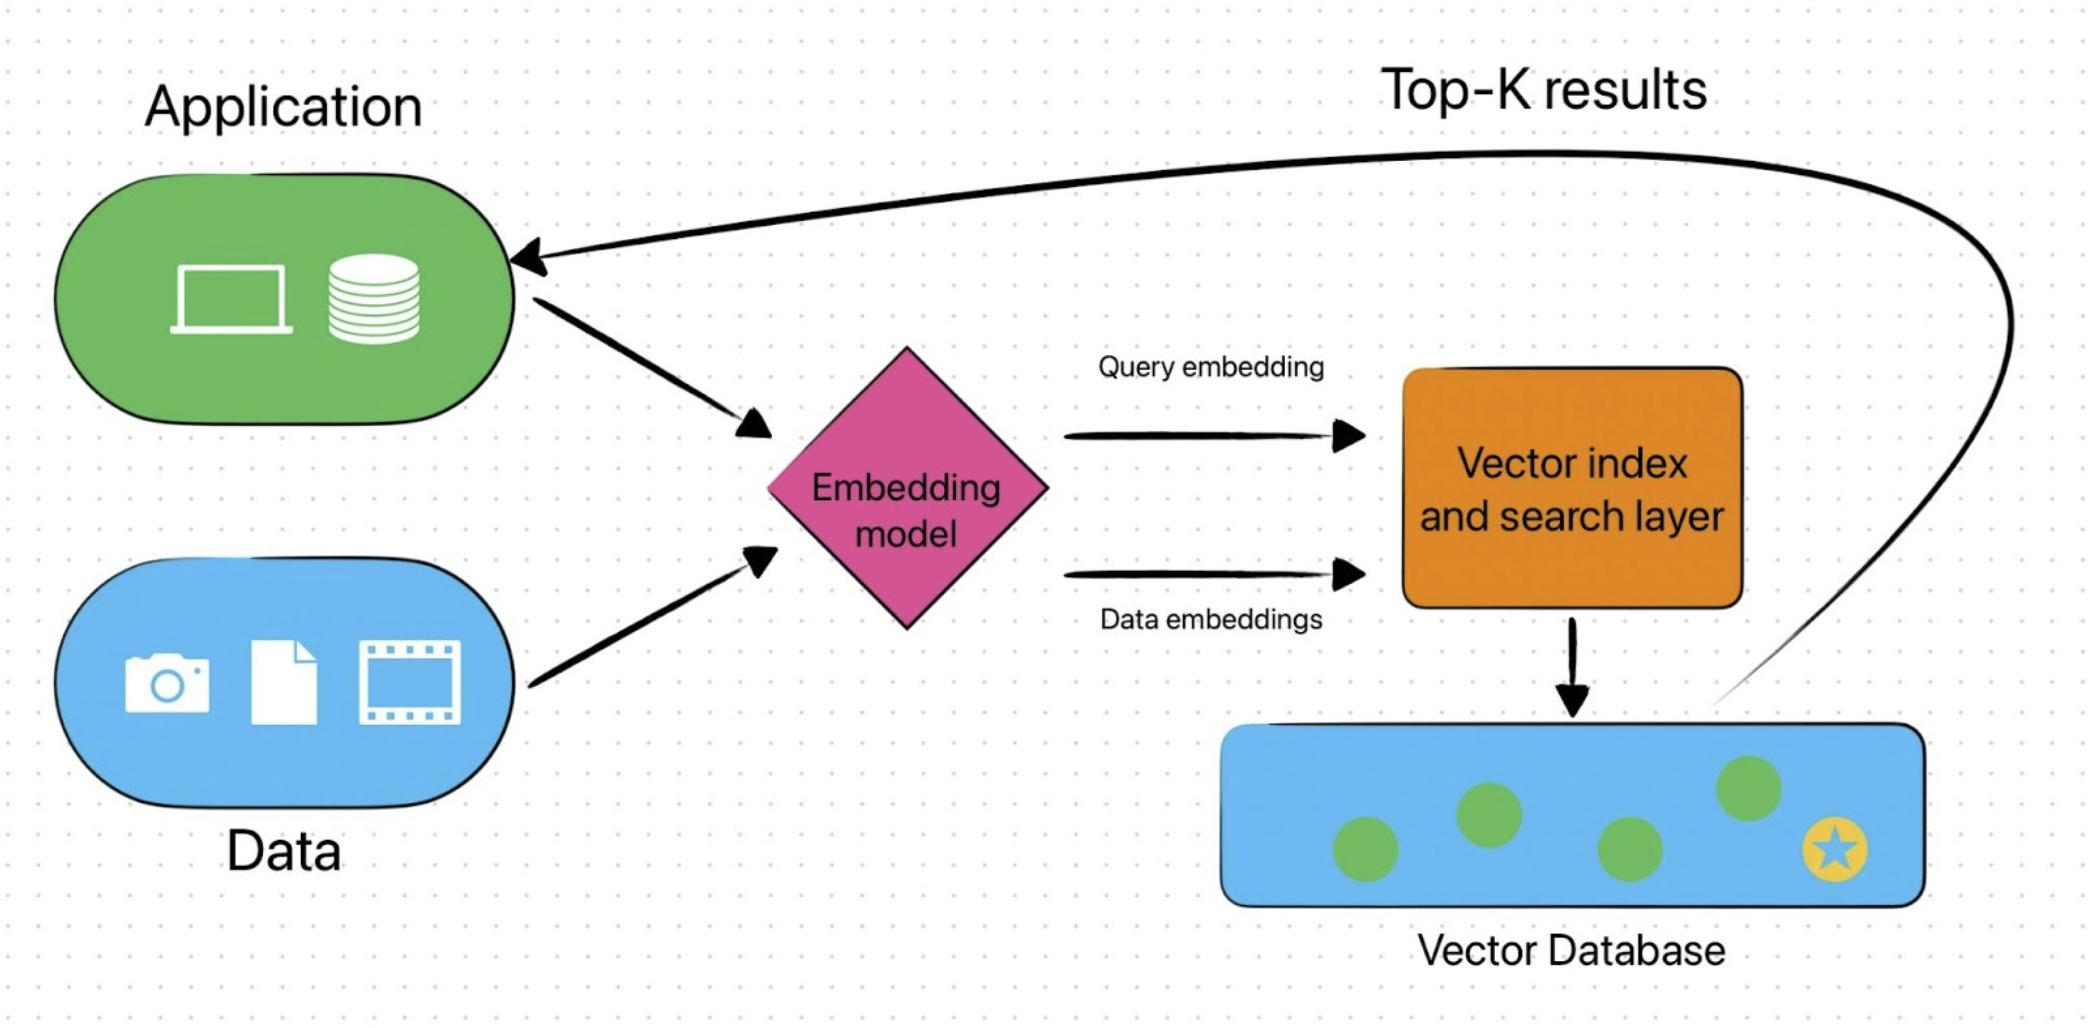

 Link : https://lantern.dev/blog/vectordb?utm_source=chatgpt.com 

In Chapter 41, you extracted text from a PDF, split it into chunks, and converted those chunks into 384-dimensional embeddings.
Now we'll build a vector database that stores those embeddings and lets us retrieve relevant chunks using semantic similarity.

PDF chunks
Text + page numbers

Embedding model
Each chunk → 384 numbers

ChromaDB
Stores vectors, text and metadata

Semantic search
Find relevant chunks for a query

# Step 1: Install ChromaDB
ChromaDB is a vector database that can store embeddings and search for similar vectors.

In [1]:
%pip install chromadb

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


# Step 2 — Import the library

In [9]:
import chromadb
import numpy as np
from sentence_transformers import SentenceTransformer

/Users/vimal/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


# Step 3 - Create a standalone dataset

In [10]:
documents = [
    "Banks monitor international payments to identify suspicious activity.",
    "Money laundering involves concealing the illegal origin of funds.",
    "Machine learning models can detect unusual transaction patterns.",
    "Credit risk models estimate the probability of a borrower defaulting.",
    "Cross-border payments transfer money between different countries.",
    "Customer due diligence helps banks verify customer identities.",
    "Neural networks can classify images and process natural language.",
    "Transaction monitoring systems generate alerts for potentially suspicious transactions."
]


In [11]:
metadatas = [
    {"category": "AML", "source": "sample", "document_number": 1},
    {"category": "AML", "source": "sample", "document_number": 2},
    {"category": "AI", "source": "sample", "document_number": 3},
    {"category": "Credit Risk", "source": "sample", "document_number": 4},
    {"category": "Payments", "source": "sample", "document_number": 5},
    {"category": "KYC", "source": "sample", "document_number": 6},
    {"category": "AI", "source": "sample", "document_number": 7},
    {"category": "AML", "source": "sample", "document_number": 8}
]

In [12]:
len(documents)

8

In [13]:
len(metadatas)

8

In [14]:
ids = [f"doc{i}" for i in range(1, len(documents) +1)]

In [ ]:
len(set(₹ids))

8

# Step 4 - Load Embedding Model

In [17]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

In [ ]:
document_embedding = model.encode(documents)

In [20]:
document_embedding.shape

(8, 384)

There are eight documents, and each is represented by a vector containing 384 numbers.
We normalize the vectors so their lengths are one. This is useful for similarity comparisons and is compatible with cosine-based retrieval

In [21]:
document_embedding[0]

array([ 3.46889980e-02, -3.86114866e-02, -7.04454407e-02, -5.25538921e-02,
        5.05712852e-02, -7.63869733e-02,  1.23750426e-01, -6.42438903e-02,
        8.83058682e-02, -1.61713210e-03, -9.51940566e-03, -1.52436104e-02,
       -1.01658106e-02,  6.40771091e-02, -8.92043710e-02, -6.91157058e-02,
       -2.63700690e-02, -2.28359103e-02,  1.57700144e-02,  2.47772895e-02,
       -2.15791967e-02, -7.93302432e-02,  4.24114615e-03,  1.44413076e-02,
       -1.53216608e-02, -1.51685784e-02,  1.04471634e-03, -1.98957277e-03,
       -3.97257842e-02, -1.07163135e-02,  5.42371348e-03,  4.65927646e-02,
       -1.21675469e-02, -1.59708820e-02,  3.31929848e-02, -6.65723458e-02,
        8.25747102e-02, -1.18141193e-02,  4.14064936e-02, -4.24151756e-02,
        5.38467765e-02, -9.36701000e-02,  1.16476335e-01, -1.55106876e-02,
       -6.57298975e-03,  4.87519987e-02,  9.24695935e-03,  6.77925944e-02,
       -5.45999072e-02,  4.11218703e-02,  1.67440195e-02, -3.12134121e-02,
        2.60961391e-02,  

In [22]:

document_embedding.shape[1]

384

# Step 5 - Create a perisistent ChromaDB Client

In [23]:
client = chromadb.PersistentClient(
    path="./chroma_db"
)

PersistentClient saves the database locally so its data can survive kernel restarts and program reruns.
Important: this notebook creates and uses a local folder named chroma_db. That folder is generated by this chapter itself; it is not an external input or a dependency on another chapter.

# Step 6 - Create a collection

In [27]:
collection = client.get_or_create_collection(
    name="chapter_42_banking_documents",
    metadata={"hnsw:space": "cosine"}
)

In [28]:
print("Collection name:", collection.name)

Collection name: chapter_42_banking_documents


A collection is a group of records stored together. Here, it holds our banking documents and their embeddings.
We configure the collection to use cosine distance. This means ChromaDB ranks vectors based on cosine distance rather than squared Euclidean distance.
Because we're using get_or_create_collection, rerunning this cell retrieves an existing collection with the same name. It doesn't automatically empty that collection.

# Step 7 — Store the documents and embeddings
Now we'll insert the IDs, original text, metadata, and precomputed vectors.

In [30]:
collection.upsert(
    ids=ids,
    documents=documents,
    metadatas=metadatas,
    embeddings=document_embedding.tolist()
)

print("Records stored:", collection.count())

Records stored: 8


# Step 8 — Inspect the stored records

In [31]:
stored_records = collection.peek(limit=3)


In [32]:
stored_records

{'ids': ['doc1', 'doc2', 'doc3'],
 'embeddings': array([[ 0.034689  , -0.03861149, -0.07044544, ..., -0.09108841,
          0.04150692, -0.10043994],
        [-0.0261731 ,  0.0164909 , -0.04233607, ..., -0.01911974,
          0.15504289, -0.02148407],
        [-0.01777143, -0.04741221, -0.00503159, ..., -0.02179348,
          0.01585749, -0.03191162]]),
 'documents': ['Banks monitor international payments to identify suspicious activity.',
  'Money laundering involves concealing the illegal origin of funds.',
  'Machine learning models can detect unusual transaction patterns.'],
 'uris': None,
 'included': ['metadatas', 'documents', 'embeddings'],
 'data': None,
 'metadatas': [{'source': 'sample', 'document_number': 1, 'category': 'AML'},
  {'source': 'sample', 'category': 'AML', 'document_number': 2},
  {'source': 'sample', 'document_number': 3, 'category': 'AI'}]}

In [33]:
stored_records["ids"]

['doc1', 'doc2', 'doc3']

In [34]:
stored_records["documents"]

['Banks monitor international payments to identify suspicious activity.',
 'Money laundering involves concealing the illegal origin of funds.',
 'Machine learning models can detect unusual transaction patterns.']

In [35]:
stored_records["metadatas"]

[{'source': 'sample', 'document_number': 1, 'category': 'AML'},
 {'source': 'sample', 'category': 'AML', 'document_number': 2},
 {'source': 'sample', 'document_number': 3, 'category': 'AI'}]

In [38]:
record = collection.get(ids = ["doc1"])

In [39]:
record

{'ids': ['doc1'],
 'embeddings': None,
 'documents': ['Banks monitor international payments to identify suspicious activity.'],
 'uris': None,
 'included': ['metadatas', 'documents'],
 'data': None,
 'metadatas': [{'source': 'sample', 'document_number': 1, 'category': 'AML'}]}

In [42]:
print(record["documents"][0][:10])

Banks moni


# Step 9 — Perform semantic search

In [44]:
query = "How can banks find suspicious international transactions?"

In [45]:
query_embedding = model.encode(query)

In [46]:
query_embedding

array([ 4.65234295e-02, -4.67716083e-02, -6.20731264e-02, -6.55625239e-02,
        3.82268354e-02, -8.30454603e-02,  1.17316395e-01, -6.81824833e-02,
        8.58327746e-02, -2.47682482e-02,  1.07165016e-02,  3.62440944e-03,
        1.05495201e-02,  3.98608893e-02, -5.14152683e-02, -6.26974553e-02,
       -4.58903611e-02, -3.57938260e-02, -1.89245753e-02, -8.84361472e-03,
       -4.03331630e-02, -6.24609850e-02, -1.39669552e-02, -2.46642046e-02,
       -5.30463969e-03, -1.67424325e-02,  4.31226939e-03, -2.36634389e-02,
       -6.01680130e-02, -2.14983039e-02, -5.33993542e-03,  6.21714555e-02,
       -4.14352491e-02, -6.44183718e-03,  6.86634034e-02, -7.52936825e-02,
        3.89332734e-02, -3.96772427e-03,  8.04497376e-02, -4.28614616e-02,
        4.98040654e-02, -9.37130824e-02,  1.13842689e-01, -1.30137301e-03,
        2.21672151e-02,  3.62676159e-02,  2.42753001e-03,  7.25299194e-02,
        4.79287514e-03,  2.59502269e-02, -9.89269931e-03, -7.35426089e-03,
        5.37715736e-04,  

In [48]:
# Retrieve the three closest documents:
results = collection.query(query_embeddings=[query_embedding.tolist()],
                           n_results=3)

In [49]:
results

{'ids': [['doc1', 'doc8', 'doc2']],
 'embeddings': None,
 'documents': [['Banks monitor international payments to identify suspicious activity.',
   'Transaction monitoring systems generate alerts for potentially suspicious transactions.',
   'Money laundering involves concealing the illegal origin of funds.']],
 'uris': None,
 'included': ['metadatas', 'documents', 'distances'],
 'data': None,
 'metadatas': [[{'document_number': 1, 'category': 'AML', 'source': 'sample'},
   {'category': 'AML', 'document_number': 8, 'source': 'sample'},
   {'document_number': 2, 'source': 'sample', 'category': 'AML'}]],
 'distances': [[0.10839694738388062, 0.46147459745407104, 0.5005051493644714]]}

In [57]:
for rank, document in enumerate(results["documents"][0],start = 1):
    metadata = results["metadatas"][0][rank - 1]
    distance = results["distances"][0][rank - 1]
    print(rank)
    print(document)
    print(metadata['category'])
    print(distance)

1
Banks monitor international payments to identify suspicious activity.
AML
0.10839694738388062
2
Transaction monitoring systems generate alerts for potentially suspicious transactions.
AML
0.46147459745407104
3
Money laundering involves concealing the illegal origin of funds.
AML
0.5005051493644714


Because the collection uses cosine distance:
- Lower distance indicates a closer vector match.
- A distance of zero indicates identical direction for nonzero vectors.
- A small distance doesn't guarantee that the document answers the question correctly.
The exact ranking depends on the embedding model and the documents in the collection.